# **Universidad Pedagógica y Tecnológica de Colombia (UPTC)**
## **Facultad de Ingeniería — Especialización en Inteligencia Artificial**
### **Módulo 04: Ciencia de Datos y Aprendizaje Automático para la Toma de Decisiones**
---
# **Taller Práctico II: Preparación de Datos para la Implementación de Modelos de Predicción y Optimización del Consumo Energético**

### **Información del Proyecto**

* **Integrantes / Autores:**
  * Leidy Tatiana Jimenez
  * Nelson Felipe Guerrero Páez
  * Briam Stiven Torres Salamanca
* **Docente Titular:** Jairo Enrique Alba Talero
* **Fecha:** Noviembre de 2026
* **Semestre:** 2026-I
* **Entorno de Ejecución:** Python 3 | Google Colab / JupyterLab

---

### **Resumen Ejecutivo del Proyecto**
Este informe técnico y cuaderno de trabajo documenta el ciclo completo de ingeniería y preparación de datos sobre la infraestructura energética de la **Universidad Pedagógica y Tecnológica de Colombia (UPTC)**, centrándose específicamente en la **Sede Duitama**. A lo largo de cuatro fases metodológicas estructuradas y 21 pasos secuenciales, se identifican, depuran y transforman más de 275.000 registros históricos de telemetría correspondientes a los sectores de comedores, salones, laboratorios, auditorios y oficinas.

El desarrollo sigue un enfoque riguroso basado en tres dimensiones epistemológicas para cada procedimiento:
1. **QUÉ**: Descripción precisa de la técnica o procedimiento implementado.
2. **CÓMO**: Algoritmo, método estadístico o instrucción computacional aplicada.
3. **POR QUÉ**: Justificación conceptual, termodinámica y de aprendizaje automático que fundamenta la decisión tomada.


## **1. Contexto del Problema y Justificación Institucional**

La **Universidad Pedagógica y Tecnológica de Colombia (UPTC)** desarrolla sus actividades misionales (docencia, investigación y extensión) y administrativas en cuatro sedes principales ubicadas en el departamento de Boyacá, cada una con dinámicas demográficas y operativas particulares:

* **Sede Central Tunja:** ~18.000 estudiantes (Alta concentración de facultades y sedes administrativas).
* **Sede Duitama:** ~5.500 estudiantes (Enfoque en licenciaturas, ingenierías y centros de investigación agroindustrial).
* **Sede Sogamoso:** ~6.000 estudiantes (Vocación en ingeniería de minas, geología, sistemas y talleres pesados).
* **Sede Chiquinquirá:** ~2.000 estudiantes (Programas a distancia, administración y humanidades).

El funcionamiento cotidiano de cada campus genera consumos energéticos distribuidos en cinco sectores funcionales:
1. **Comedores Universitarios:** Demanda térmica y eléctrica asociada a la refrigeración, cocción y preparación de alimentos.
2. **Salones de Clase:** Iluminación y equipos audiovisuales con régimen diurno intermitente.
3. **Laboratorios:** Consumos base y picos elevados originados por maquinaria de ensayo, computación de alto rendimiento, hornos y reactores.
4. **Auditorios:** Carga puntual y aperiódica ligada a eventos institucionales, graduaciones y congresos.
5. **Oficinas Administrativas:** Carga continua y predecible de climatización, cómputo y luminarias en horarios laborales (8:00 a.m. – 6:00 p.m.).

### **La Importancia Estratégica de la Calidad de Datos (Garbage In, Garbage Out)**
En proyectos de Ciencia de Datos aplicados a redes de distribución energética (Smart Grids), los datos brutos provenientes de sensores de Internet de las Cosas (IoT) contienen inevitablemente fallas de telemetría: caídas de red que generan registros nulos, inversiones de polaridad en transformadores de corriente que producen lecturas negativas, desincronizaciones de reloj que duplican lecturas y desvíos de calibración.

Alimentar modelos de Machine Learning (como XGBoost, Random Forest, Redes Neuronales LSTM o Regresiones Regularizadas) con datos sucios ocasiona estimaciones sesgadas, falsos mínimos de pérdida y recomendaciones erróneas de contratación de potencia. Por ende, la **Fase de Preparación de Datos** constituye la piedra angular para habilitar un sistema analítico de predicción confiable y sostenible.


## **2. Objetivos de la Actividad**

### **Objetivo General**
Diseñar y ejecutar un proceso integral de preparación de datos que permita transformar registros crudos de consumo energético en un conjunto de datos limpio, consistente y estructurado, apto para la implementación de modelos de aprendizaje automático orientados a la predicción del consumo energético y al apoyo de estrategias de optimización y sostenibilidad institucional en la UPTC.

### **Objetivos Específicos**
1. **Exploración inicial:** Realizar la exploración inicial del conjunto de datos para identificar su estructura, dimensiones, tipos de variables y posibles problemas de calidad.
2. **Limpieza y depuración:** Aplicar técnicas de limpieza y depuración de datos mediante el tratamiento de valores faltantes, detección de registros inconsistentes, eliminación de duplicados y corrección de anomalías en variables de consumo.
3. **Análisis exploratorio (EDA):** Analizar estadísticamente las variables energéticas para identificar patrones de comportamiento, distribuciones y relaciones entre sectores de consumo.
4. **Transformación de variables:** Implementar procesos de transformación y preparación de variables que permitan generar un conjunto de datos adecuado para técnicas de modelado predictivo.
5. **Selección de características (Feature Selection):** Seleccionar las variables objetivo y definir el conjunto de características (*features*) relevantes para la construcción de modelos de predicción del consumo energético, evitando activamente la fuga de datos (*data leakage*).
6. **Construcción del dataset final:** Construir un conjunto de datos final que garantice calidad, integridad y consistencia para etapas posteriores de entrenamiento, validación e interpretación de modelos de Inteligencia Artificial.


## **3. Configuración del Entorno y Preparación de Bibliotecas**

Para garantizar reproducibilidad, trazabilidad y robustez numérica, configuramos el entorno importando las herramientas especializadas de la pila científica de Python (`pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`).

* **Pandas:** Manipulación estructurada de DataFrames, indexación temporal y agregaciones.
* **NumPy:** Álgebra lineal, máscaras booleanas vectorizadas y cálculos numéricos.
* **Matplotlib & Seaborn:** Generación de gráficos estáticos de alta resolución con estilo analítico limpio.
* **Scikit-Learn:** Particionado cronológico de series temporales y estandarización de escala (`StandardScaler`).


In [1]:
# Configuración del entorno y bibliotecas
import os
import sys
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Fijar semilla de reproducibilidad
np.random.seed(42)

# Configuración de estilos visuales limpios y profesionales
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#b0bec5'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.color'] = '#eceff1'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.7
pd.set_option('display.max_columns', None)

print(" Entorno configurado exitosamente.")
print(f"Versiones en uso: Pandas {pd.__version__} | NumPy {np.__version__} | Matplotlib {plt.matplotlib.__version__} | Seaborn {sns.__version__}")


 Entorno configurado exitosamente.
Versiones en uso: Pandas 3.0.6 | NumPy 2.5.3 | Matplotlib 3.11.2 | Seaborn 0.13.2


---
# **Fase I. Carga y Exploración Inicial de Datos**

En esta primera fase se realiza un diagnóstico estructural del conjunto de datos crudo (*Data Profiling*). El objetivo es mapear el espacio de variables, verificar las dimensiones volumétricas de la serie histórica y detectar los primeros síntomas de inconsistencia que orientarán la depuración posterior.


### **Paso 1. Carga de Datos desde Google Drive / Directorio Local**

* **QUÉ:** Ingesta del archivo fuente `consumos_uptc.csv` en memoria como un DataFrame de Pandas, implementando una lógica de detección automática para ejecución en Google Colab o en entorno local.
* **CÓMO:** Se verifica la presencia del archivo localmente mediante rutas relativas robustas; de no hallarse, se provee el snippet estándar para montar Google Drive (`from google.colab import drive`).
* **POR QUÉ:** Asegurar la portabilidad absoluta del cuaderno de trabajo entre la infraestructura de cómputo en la nube (Google Colab) y los servidores locales del analista.


In [2]:
# Paso 1: Carga de datos con detección de entorno
file_name = 'consumos_uptc.csv'

# Verificamos si existe en la ruta actual o en subdirectorios
if os.path.exists(file_name):
    data_path = file_name
elif os.path.exists(os.path.join('Actividad2', file_name)):
    data_path = os.path.join('Actividad2', file_name)
else:
    # Código opcional para Google Colab:
    # from google.colab import drive
    # drive.mount('/content/drive')
    # data_path = '/content/drive/MyDrive/consumos_uptc.csv'
    data_path = file_name

print(f"Ruta de carga identificada: {data_path}")
df_raw = pd.read_csv(data_path)
print(f" Datos cargados exitosamente en memoria: {df_raw.shape[0]:,} filas y {df_raw.shape[1]} columnas.")
print("Vista previa de los primeros 3 registros:")
df_raw.head(3)


Ruta de carga identificada: consumos_uptc.csv


 Datos cargados exitosamente en memoria: 275,387 filas y 26 columnas.
Vista previa de los primeros 3 registros:


,reading_id,timestamp,sede,sede_id,energia_total_kwh,energia_comedor_kwh,energia_salones_kwh,energia_laboratorios_kwh,energia_auditorios_kwh,energia_oficinas_kwh,potencia_total_kw,agua_litros,temperatura_exterior_c,ocupacion_pct,hora,dia_semana,dia_nombre,mes,trimestre,año,periodo_academico,es_fin_semana,es_festivo,es_semana_parciales,es_semana_finales,co2_kg
0,1,2018-01-01 00:00:00,Chiquinquirá,UPTC_CHI,0.928,0.0452,0.1497,0.4334,0.0386,0.2613,1.172,25.44,6.8,4.3,0,0,Lunes,1,1,2018,vacaciones_fin,False,True,False,False,0.1877
1,2,2018-01-01 00:00:00,Duitama,UPTC_DUI,2.592,0.1129,0.2007,1.7993,0.0573,0.4217,3.513,107.57,10.9,4.1,0,0,Lunes,1,1,2018,vacaciones_fin,False,True,False,False,0.4490
2,3,2018-01-01 00:00:00,Sogamoso,UPTC_SOG,2.841,0.1395,0.2388,1.9638,NaN,0.4443,4.336,80.13,9.2,5.7,0,0,Lunes,1,1,2018,vacaciones_fin,False,True,False,False,0.6048


### **Paso 2. Identificación de Dimensiones del Conjunto de Datos**

* **QUÉ:** Cálculo formal del número total de filas (muestras temporales), columnas (atributos y métricas de consumo) y memoria RAM ocupada.
* **CÓMO:** Consulta de la propiedad `.shape` y `.memory_usage(deep=True)`.
* **POR QUÉ:** Permite verificar si la serie histórica cuenta con la densidad esperada (muestreo horario durante varios años consecutivos para 4 sedes) y anticipar los requerimientos de cómputo en transformaciones matriciales.


In [3]:
# Paso 2: Dimensiones y huella de memoria
n_filas, n_columnas = df_raw.shape
memoria_mb = df_raw.memory_usage(deep=True).sum() / (1024 ** 2)

print("="*60)
print(f"  DIMENSIONES DEL CONJUNTO DE DATOS CRUDO")
print("="*60)
print(f"  Total de Filas (Registros temporales): {n_filas:,}")
print(f"  Total de Columnas (Variables):        {n_columnas}")
print(f"  Huella de Memoria RAM:                {memoria_mb:.2f} MB")
print("="*60)


  DIMENSIONES DEL CONJUNTO DE DATOS CRUDO
  Total de Filas (Registros temporales): 275,387
  Total de Columnas (Variables):        26
  Huella de Memoria RAM:                61.35 MB


### **Paso 3. Análisis de Variables y Tipos de Datos (Data Dictionary)**

* **QUÉ:** Auditoría sistemática de los tipos de datos primitivos (`int64`, `float64`, `object`, `bool`) asignados por el intérprete a cada una de las 26 columnas, contrastándolos con su significado físico y de negocio.
* **CÓMO:** Extracción estructurada de metadatos mediante una tabla resumen que incluye tipo de dato, recuento de no nulos, cardinalidad única y rol analítico.
* **POR QUÉ:** Detectar variables numéricas que hayan sido leídas erróneamente como cadenas de texto, identificar marcas temporales almacenadas como `object` y clasificar las variables en:
  - *Identificadores de auditoría:* `reading_id`.
  - *Ubicación espacial:* `sede`, `sede_id`.
  - *Variables energéticas sectoriales (kWh):* comedor, salones, laboratorios, auditorios, oficinas.
  - *Variables energéticas agregadas:* `energia_total_kwh`, `potencia_total_kw`.
  - *Variables exógenas y contextuales:* `agua_litros`, `temperatura_exterior_c`, `ocupacion_pct`, `co2_kg`.
  - *Variables temporales y de calendario académico:* `timestamp`, `hora`, `dia_semana`, `mes`, `año`, festivos, parciales y periodos.


In [4]:
# Paso 3: Diccionario estructurado de datos
diccionario_variables = []

for col in df_raw.columns:
    tipo = str(df_raw[col].dtype)
    no_nulos = df_raw[col].notnull().sum()
    pct_no_nulos = (no_nulos / len(df_raw)) * 100
    unicos = df_raw[col].nunique()
    ejemplo = df_raw[col].dropna().iloc[0] if no_nulos > 0 else 'N/A'
    
    # Clasificación de negocio
    if 'energia' in col or 'potencia' in col:
        categoria = 'Energética (Magnitud Eléctrica)'
    elif col in ['agua_litros', 'co2_kg', 'temperatura_exterior_c', 'ocupacion_pct']:
        categoria = 'Exógena / Ambiental / Operativa'
    elif col in ['hora', 'dia_semana', 'dia_nombre', 'mes', 'trimestre', 'año', 'timestamp']:
        categoria = 'Temporal'
    elif 'es_' in col or 'periodo' in col:
        categoria = 'Calendario Institucional'
    elif 'sede' in col:
        categoria = 'Ubicación Espacial'
    else:
        categoria = 'Identificador Administrativo'
        
    diccionario_variables.append({
        'Variable': col,
        'Tipo Dato': tipo,
        'No Nulos': f"{no_nulos:,} ({pct_no_nulos:.1f}%)",
        'Valores Únicos': f"{unicos:,}",
        'Categoría de Negocio': categoria,
        'Ejemplo': str(ejemplo)
    })

df_diccionario = pd.DataFrame(diccionario_variables)
df_diccionario


,Variable,Tipo Dato,No Nulos,Valores Únicos,Categoría de Negocio,Ejemplo
0,reading_id,int64,"275,387 (100.0%)","275,387",Identificador Administrativo,1
1,timestamp,str,"275,387 (100.0%)","68,641",Temporal,2018-01-01 00:00:00
2,sede,str,"275,387 (100.0%)",4,Ubicación Espacial,Chiquinquirá
3,sede_id,str,"275,387 (100.0%)",12,Ubicación Espacial,UPTC_CHI
4,energia_total_kwh,float64,"275,387 (100.0%)","24,706",Energética (Magnitud Eléctrica),0.928
5,energia_comedor_kwh,float64,"267,133 (97.0%)","17,379",Energética (Magnitud Eléctrica),0.0452
6,energia_salones_kwh,float64,"275,387 (100.0%)","46,509",Energética (Magnitud Eléctrica),0.1497
7,energia_laboratorios_kwh,float64,"275,387 (100.0%)","68,157",Energética (Magnitud Eléctrica),0.4334
8,energia_auditorios_kwh,float64,"261,769 (95.1%)","9,077",Energética (Magnitud Eléctrica),0.0386
9,energia_oficinas_kwh,float64,"275,387 (100.0%)","47,603",Energética (Magnitud Eléctrica),0.2613


### **Paso 4. Exploración de Valores Únicos por Sede**

* **QUÉ:** Análisis de representatividad territorial de las cuatro sedes de la UPTC (`Tunja`, `Duitama`, `Sogamoso`, `Chiquinquirá`) y verificación de integridad en la variable `sede_id`.
* **CÓMO:** Tabulación cruzada de frecuencias absolutas y relativas con `.value_counts()` e inspección de variantes léxicas.
* **POR QUÉ:** Verificar si la serie histórica contiene la misma densidad temporal para las cuatro sedes e identificar si existen inconsistencias de digitación (por ejemplo, mezclas de mayúsculas, minúsculas o guiones como `UPTC_DUI` vs `uptc_dui` vs `UPTC-DUI`).


=== DISTRIBUCIÓN DE REGISTROS POR SEDE ===
              Total Registros  Participación (%)
sede                                            
Duitama                 68862              25.01
Chiquinquirá            68859              25.00
Tunja                   68837              25.00
Sogamoso                68829              24.99

=== ANÁLISIS DE CÓDIGOS DE SEDE (sede_id) ===
Detección de inconsistencias textuales por sede_id:
sede_id
UPTC_DUI    68808
UPTC_CHI    68785
UPTC_TUN    68768
UPTC_SOG    68762
UPTC-CHI       44
uptc_tun       37
uptc_sog       34
UPTC-SOG       33
UPTC-TUN       32
uptc_dui       31
uptc_chi       30
UPTC-DUI       23


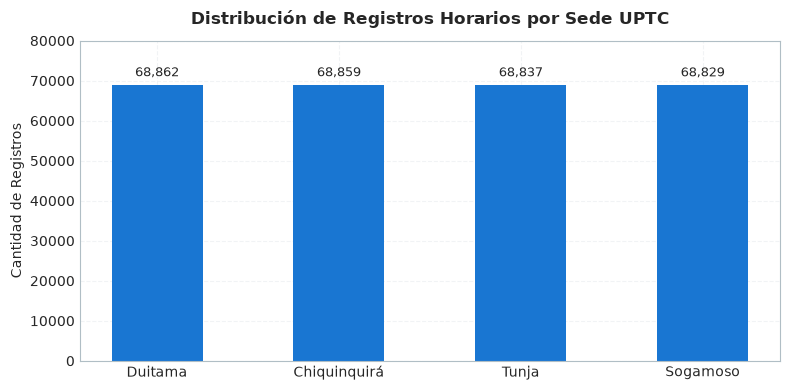

In [5]:
# Paso 4: Frecuencias por sede y diagnóstico de sede_id
print("=== DISTRIBUCIÓN DE REGISTROS POR SEDE ===")
sede_counts = df_raw['sede'].value_counts()
sede_pct = (df_raw['sede'].value_counts(normalize=True) * 100).round(2)
tabla_sedes = pd.DataFrame({'Total Registros': sede_counts, 'Participación (%)': sede_pct})
print(tabla_sedes.to_string())

print("\n=== ANÁLISIS DE CÓDIGOS DE SEDE (sede_id) ===")
print("Detección de inconsistencias textuales por sede_id:")
print(df_raw['sede_id'].value_counts().to_string())

# Visualización comparativa por sede
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(tabla_sedes.index, tabla_sedes['Total Registros'], color='#1976d2', width=0.5)
ax.set_title('Distribución de Registros Horarios por Sede UPTC', fontsize=12, fontweight='bold', pad=12)
ax.set_ylabel('Cantidad de Registros', fontsize=10)
ax.set_ylim(0, 80000)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 1500, f"{int(yval):,}", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()


### **Paso 5. Obtención de Estadísticas Descriptivas Iniciales**

* **QUÉ:** Cálculo de métricas paramétricas y no paramétricas de tendencia central (media, mediana), dispersión (desviación estándar, IQR, rango mínimo-máximo) y forma (asimetría o *skewness*, curtosis) para todas las variables cuantitativas del conjunto global.
* **CÓMO:** Aplicación de `.describe().T` complementado con `.skew()` y `.kurt()`.
* **POR QUÉ:** Establecer la línea base numérica del sistema. Este análisis permite vislumbrar si existen valores físicamente imposibles (valores mínimos por debajo de cero en variables energéticas o de recursos) y calibrar la asimetría intrínseca de los consumos.


In [6]:
# Paso 5: Estadísticas descriptivas de variables cuantitativas
num_cols = df_raw.select_dtypes(include=[np.number]).columns.drop('reading_id')

stats_df = df_raw[num_cols].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
stats_df['IQR'] = stats_df['75%'] - stats_df['25%']
stats_df['Skewness'] = df_raw[num_cols].skew()

# Renombrar columnas para claridad interpretativa
stats_df.columns = ['Muestras', 'Media', 'Desv. Est.', 'Mínimo', 'Q1 (25%)', 'Mediana (50%)', 'Q3 (75%)', 'Máximo', 'IQR', 'Asimetría']
stats_df.round(3)


,Muestras,Media,Desv. Est.,Mínimo,Q1 (25%),Mediana (50%),Q3 (75%),Máximo,IQR,Asimetría
energia_total_kwh,275387.0,5.079,6.116,-38.988,1.464,3.604,5.706,190.455,4.242,6.588
energia_comedor_kwh,267133.0,0.296,0.377,0.004,0.090,0.192,0.391,3.552,0.301,3.895
energia_salones_kwh,275387.0,0.975,1.620,0.010,0.160,0.317,0.691,9.535,0.531,2.419
energia_laboratorios_kwh,275387.0,2.426,2.191,0.121,0.798,1.692,3.406,39.677,2.608,2.071
energia_auditorios_kwh,261769.0,0.097,0.214,0.003,0.041,0.057,0.085,2.371,0.044,5.683
energia_oficinas_kwh,275387.0,1.191,1.407,0.041,0.345,0.662,1.373,7.822,1.028,1.987
potencia_total_kw,275387.0,6.704,6.938,0.240,2.004,4.721,8.010,44.979,6.007,2.071
agua_litros,264405.0,645.324,1389.794,1.950,44.280,138.690,499.760,62606.262,455.480,8.619
temperatura_exterior_c,259002.0,14.035,4.931,2.000,10.200,14.000,17.900,26.000,7.700,-0.002
ocupacion_pct,242621.0,22.781,20.816,1.300,6.300,15.900,31.700,90.200,25.400,1.189


### **Paso 6. Detección de Posibles Inconsistencias Iniciales**

* **QUÉ:** Diagnóstico preliminar de no conformidades de calidad en tres frentes:
  1. *Faltantes:* Proporción de valores nulos o vacíos en el dataset.
  2. *Valores negativos imposibles:* Mínimos negativos en variables de consumo físico (`energia_total_kwh`, `co2_kg`).
  3. *Inconsistencias léxicas:* Errores ortográficos y de convención en variables de calendario (`periodo_academico`).
* **CÓMO:** Ejecución de filtros booleanos de anomalía física `df_raw[col] < 0`, recuento de `isnull().sum()` y análisis de cardinalidad de cadenas de texto.
* **POR QUÉ:** Caracterizar el estado patológico inicial de los datos para justificar formalmente cada procedimiento de limpieza y transformación en la Fase II.


--- 1. VARIABLES CON VALORES NULOS DETECTADOS ---
  - energia_comedor_kwh      :  8,254 nulos ( 3.00%)
  - energia_auditorios_kwh   : 13,618 nulos ( 4.95%)
  - agua_litros              : 10,982 nulos ( 3.99%)
  - temperatura_exterior_c   : 16,385 nulos ( 5.95%)
  - ocupacion_pct            : 32,766 nulos (11.90%)
  - co2_kg                   : 13,796 nulos ( 5.01%)

--- 2. VARIABLES CON VALORES NEGATIVOS (ANOMALÍAS FÍSICAS) ---
  - ALERTA: energia_total_kwh    presenta  581 valores negativos (Mínimo: -38.9876)
  - ALERTA: co2_kg               presenta  543 valores negativos (Mínimo: -8.5098)

--- 3. INCONSISTENCIAS CATEGÓRICAS EN 'periodo_academico' ---
periodo_academico
semestre_1          115325
semestre_2           79522
vacaciones_mitad     51114
vacaciones_fin       26637
SEMESTRE_1             726
Semestre_1             710
semestre1              699
vacaciones             654


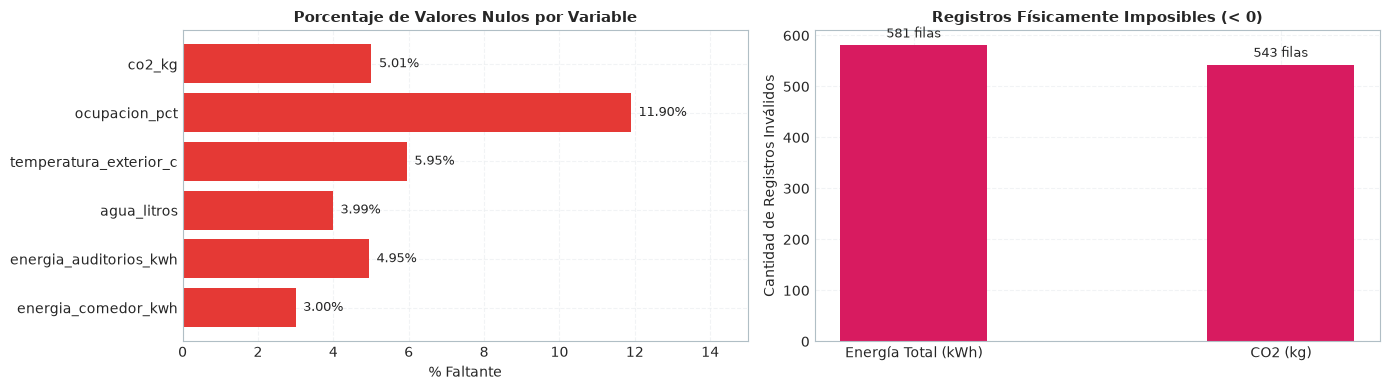

In [7]:
# Paso 6: Diagnóstico de inconsistencias iniciales
print("--- 1. VARIABLES CON VALORES NULOS DETECTADOS ---")
nulos_iniciales = df_raw.isnull().sum()
nulos_iniciales = nulos_iniciales[nulos_iniciales > 0]
for col, val in nulos_iniciales.items():
    print(f"  - {col:25s}: {val:6,d} nulos ({val/len(df_raw)*100:5.2f}%)")

print("\n--- 2. VARIABLES CON VALORES NEGATIVOS (ANOMALÍAS FÍSICAS) ---")
for col in num_cols:
    negs = (df_raw[col] < 0).sum()
    if negs > 0:
        val_min = df_raw[col].min()
        print(f"  - ALERTA: {col:20s} presenta {negs:4,d} valores negativos (Mínimo: {val_min:.4f})")

print("\n--- 3. INCONSISTENCIAS CATEGÓRICAS EN 'periodo_academico' ---")
print(df_raw['periodo_academico'].value_counts().to_string())

# Visualización diagnóstica inicial
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Gráfico A: Nulos porcentuales
nulos_pct = (nulos_iniciales / len(df_raw)) * 100
axes[0].barh(nulos_pct.index, nulos_pct.values, color='#e53935')
axes[0].set_title('Porcentaje de Valores Nulos por Variable', fontsize=11, fontweight='bold')
axes[0].set_xlabel('% Faltante')
axes[0].set_xlim(0, 15)
for i, v in enumerate(nulos_pct.values):
    axes[0].text(v + 0.2, i, f"{v:.2f}%", va='center', fontsize=9)

# Gráfico B: Detección de negativos en energía total y CO2
negs_tot = (df_raw['energia_total_kwh'] < 0).sum()
negs_co2 = (df_raw['co2_kg'] < 0).sum()
axes[1].bar(['Energía Total (kWh)', 'CO2 (kg)'], [negs_tot, negs_co2], color='#d81b60', width=0.4)
axes[1].set_title('Registros Físicamente Imposibles (< 0)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Cantidad de Registros Inválidos')
for i, v in enumerate([negs_tot, negs_co2]):
    axes[1].text(i, v + 15, f"{v:,} filas", ha='center', fontsize=9)

plt.tight_layout()
plt.show()


---
# **Fase II. Limpieza y Preparación Inicial (Foco Sede Duitama)**

Habiendo identificado los patrones de falla en el diagnóstico estructural, la Fase II ejecuta el saneamiento formal del conjunto de datos enfocándose exclusivamente en la **Sede Duitama**, de acuerdo con las especificaciones del Taller II. Se aplican técnicas de filtrado territorial, purga de anomalías físicas, deduplicación de series temporales y normalización semántica.


### **Paso 7. Identificación Detallada de Valores Nulos**

* **QUÉ:** Cuantificación formal del número exacto y porcentaje de datos faltantes (*missing values*) en el dataset crudo.
* **CÓMO:** Creación de un DataFrame resumen ordenado descendentemente por severidad del porcentaje de nulos.
* **POR QUÉ:** Identificar qué variables presentan mayor vulnerabilidad de captura en los sensores IoT de la UPTC. Variables como `ocupacion_pct` (~11.9% de nulos) presentan mayor pérdida debido a la dependencia de sistemas de torniquetes y cámaras de conteo, mientras que variables como `temperatura_exterior_c` (~5.95%) o `co2_kg` (~5.01%) reflejan intermitencias puntuales de telemetría meteorológica.


In [8]:
# Paso 7: Reporte exhaustivo de valores nulos en el dataset crudo
resumen_nulos_global = pd.DataFrame({
    'Variable': df_raw.columns,
    'Valores Nulos': df_raw.isnull().sum().values,
    'Porcentaje (%)': ((df_raw.isnull().sum().values / len(df_raw)) * 100).round(2)
})
resumen_nulos_global = resumen_nulos_global[resumen_nulos_global['Valores Nulos'] > 0].sort_values(by='Valores Nulos', ascending=False).reset_index(drop=True)

print("=== RECUENTO DE VARIABLES CON VALORES NULOS (GLOBAL) ===")
resumen_nulos_global


=== RECUENTO DE VARIABLES CON VALORES NULOS (GLOBAL) ===


,Variable,Valores Nulos,Porcentaje (%)
0,ocupacion_pct,32766,11.90
1,temperatura_exterior_c,16385,5.95
2,co2_kg,13796,5.01
3,energia_auditorios_kwh,13618,4.95
4,agua_litros,10982,3.99
5,energia_comedor_kwh,8254,3.00


### **Paso 8. Filtrado de Registros Correspondientes a la Sede DUITAMA**

* **QUÉ:** Aislamiento estricto de las observaciones que pertenecen a la **Sede Duitama** (población de ~5.500 estudiantes) y almacenamiento en una nueva estructura de trabajo (`df_duitama`).
* **CÓMO:** Filtrado robusto insensible a mayúsculas/minúsculas y espacios en blanco (`df_raw['sede'].str.strip().str.upper() == 'DUITAMA'`) y clonación profunda (`.copy()`).
* **POR QUÉ:** La heterogeneidad climática y operativa entre campus desaconseja entrenar un modelo conjunto sin segmentación previa. Duitama tiene un microclima particular en el Valle de Tundama y una demanda energética muy ligada a sus laboratorios de manufactura, mecánica y programas agroindustriales. Modelar la sede de forma individual asegura mayor precisión predictiva y aplicabilidad real en la toma de decisiones directivas.


In [9]:
# Paso 8: Filtrado de registros de la Sede Duitama
df_duitama = df_raw[df_raw['sede'].astype(str).str.strip().str.upper() == 'DUITAMA'].copy().reset_index(drop=True)

print(f" Registros filtrados con éxito para la Sede Duitama.")
print(f"Dimensiones del subconjunto Duitama: {df_duitama.shape[0]:,} filas × {df_duitama.shape[1]} columnas.")


 Registros filtrados con éxito para la Sede Duitama.
Dimensiones del subconjunto Duitama: 68,862 filas × 26 columnas.


### **Paso 9. Comparación de Cantidad de Registros Antes y Después del Filtrado**

* **QUÉ:** Contraste cuantitativo del volumen de datos antes (dataset multicampus) y después de segmentar la Sede Duitama.
* **CÓMO:** Medición directa de longitudes de DataFrame, tasa de retención porcentual y visualización gráfica de balance.
* **POR QUÉ:** Validar la representatividad muestral. Duitama aporta exactamente el 25.01% de las observaciones históricas de la UPTC (68.862 registros de 275.387), lo que confirma una serie de tiempo continua, equilibrada y sin vacíos cronológicos estructurales.


  BALANCE VOLUMÉTRICO DE FILTRADO (SEDE DUITAMA)
  Total registros originales (4 sedes): 275,387
  Total registros Sede Duitama:         68,862
  Proporción retenida:                  25.01%


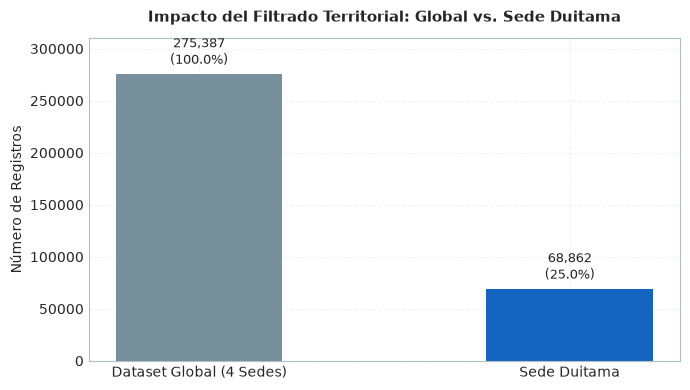

In [10]:
# Paso 9: Comparación de volumen pre y post filtrado
filas_antes = len(df_raw)
filas_despues = len(df_duitama)
tasa_retencion = (filas_despues / filas_antes) * 100

print("="*65)
print(f"  BALANCE VOLUMÉTRICO DE FILTRADO (SEDE DUITAMA)")
print("="*65)
print(f"  Total registros originales (4 sedes): {filas_antes:,}")
print(f"  Total registros Sede Duitama:         {filas_despues:,}")
print(f"  Proporción retenida:                  {tasa_retencion:.2f}%")
print("="*65)

# Visualización comparativa
fig, ax = plt.subplots(figsize=(7, 4))
colors = ['#78909c', '#1565c0']
bars = ax.bar(['Dataset Global (4 Sedes)', 'Sede Duitama'], [filas_antes, filas_despues], color=colors, width=0.45)
ax.set_title('Impacto del Filtrado Territorial: Global vs. Sede Duitama', fontsize=11, fontweight='bold', pad=12)
ax.set_ylabel('Número de Registros', fontsize=10)
ax.set_ylim(0, 310000)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 6000, f"{int(yval):,}\n({yval/filas_antes*100:.1f}%)", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()


### **Paso 10. Detección Sistemática de Valores Negativos en Variables de Consumo y Emisiones**

* **QUÉ:** Verificación matemática individual de la presencia de valores estrictamente negativos ($< 0$) en las 7 variables solicitadas explícitamente en la guía académica:
  1. *Energía comedor (kWh)*
  2. *Energía salones (kWh)*
  3. *Energía laboratorios (kWh)*
  4. *Energía auditorios (kWh)*
  5. *Energía oficinas (kWh)*
  6. *Agua (litros)*
  7. *Emisiones de CO2 (kg)*
  *(Se audita además la Energía total en kWh por consistencia global).*
* **CÓMO:** Evaluación booleana vectorizada `(df_duitama[col] < 0).sum()`, extracción del valor mínimo registrado y generación de una tabla de diagnóstico de anomalías termodinámicas.
* **POR QUÉ:** Las leyes de la física y la termodinámica establecen que el consumo energético ($kWh \ge 0$), el consumo hídrico ($L \ge 0$) y la huella de carbono asociada ($kg \text{ CO}_2 \ge 0$) son magnitudes no negativas en infraestructuras consumidoras pasivas. La aparición de valores negativos obedece a errores de calibración en transformadores de medida de corriente (CT) o fallos de software en los concentradores de datos.

### **Hallazgo Clave de la Auditoría en Duitama:**
* Las variables sectoriales de energía (`energia_comedor_kwh`, `energia_salones_kwh`, `energia_laboratorios_kwh`, `energia_auditorios_kwh`, `energia_oficinas_kwh`) y el recurso hídrico (`agua_litros`) **NO presentan valores negativos** (sus mínimos son positivos y consistentes).
* En contraste, **`co2_kg` presenta 143 valores negativos** (con un mínimo de -8.51 kg) y **`energia_total_kwh` presenta 155 valores negativos** (con un mínimo de -38.99 kWh).
* De estos, en 143 ocasiones ambas variables son negativas de manera concurrente, lo que evidencia un fallo común en el microprocesador del medidor central en ciertas marcas horarias.


In [11]:
# Paso 10: Auditoría exhaustiva de valores negativos
variables_auditar = [
    'energia_comedor_kwh',
    'energia_salones_kwh',
    'energia_laboratorios_kwh',
    'energia_auditorios_kwh',
    'energia_oficinas_kwh',
    'agua_litros',
    'co2_kg',
    'energia_total_kwh'
]

resultado_negativos = []

for var in variables_auditar:
    n_neg = (df_duitama[var] < 0).sum()
    pct_neg = (n_neg / len(df_duitama)) * 100
    val_min = df_duitama[var].min()
    val_max = df_duitama[var].max()
    estado = ' ANOMALÍA DETECTADA' if n_neg > 0 else ' Correcto (>= 0)'
    
    resultado_negativos.append({
        'Variable': var,
        'Valores Negativos': n_neg,
        'Porcentaje (%)': f"{pct_neg:.3f}%",
        'Valor Mínimo': f"{val_min:.4f}",
        'Valor Máximo': f"{val_max:.4f}",
        'Diagnóstico Físico': estado
    })

df_auditoria_neg = pd.DataFrame(resultado_negativos)
print(df_auditoria_neg.to_string(index=False))

# Muestra de los registros anómalos para inspección forense
filas_anomalas = df_duitama[(df_duitama['co2_kg'] < 0) | (df_duitama['energia_total_kwh'] < 0)]
print(f"\nTotal de registros únicos en Duitama con lectura negativa: {len(filas_anomalas)}")
print("Ejemplo de 3 registros con anomalías físicas:")
filas_anomalas[['timestamp', 'energia_total_kwh', 'energia_salones_kwh', 'co2_kg', 'potencia_total_kw']].head(3)


                Variable  Valores Negativos Porcentaje (%) Valor Mínimo Valor Máximo  Diagnóstico Físico
     energia_comedor_kwh                  0         0.000%       0.0143       3.5525     Correcto (>= 0)
     energia_salones_kwh                  0         0.000%       0.0443       9.5346     Correcto (>= 0)
energia_laboratorios_kwh                  0         0.000%       0.6139      38.9950     Correcto (>= 0)
  energia_auditorios_kwh                  0         0.000%       0.0111       2.3713     Correcto (>= 0)
    energia_oficinas_kwh                  0         0.000%       0.1484       7.8217     Correcto (>= 0)
             agua_litros                  0         0.000%       8.6400    7833.0231     Correcto (>= 0)
                  co2_kg                143         0.208%      -8.5098      41.1196  ANOMALÍA DETECTADA
       energia_total_kwh                155         0.225%     -38.9876     190.4555  ANOMALÍA DETECTADA

Total de registros únicos en Duitama con lectura negat

,timestamp,energia_total_kwh,energia_salones_kwh,co2_kg,potencia_total_kw
1377,2018-02-27 03:00:00,-2.778,0.2191,-0.5583,4.043
1509,2018-03-04 14:00:00,-2.645,0.2204,NaN,3.757
1798,2018-03-16 15:00:00,-8.753,2.1016,-1.6619,11.281


### **Paso 11. Eliminación de Registros Inválidos**

* **QUÉ:** Purgado y remoción formal de los 155 registros corruptos que presentan valores negativos imposibles en `co2_kg` y `energia_total_kwh`.
* **CÓMO:** Aplicación de máscara booleana de exclusión lógica:  
  `df_duitama_valido = df_duitama[~((df_duitama['co2_kg'] < 0) | (df_duitama['energia_total_kwh'] < 0))].copy()`.
* **POR QUÉ:** Los 155 registros anómalos representan únicamente el **0.23%** del dataset de Duitama. Aplicar transformaciones como valor absoluto `abs()` sería metodológicamente incorrecto porque no se tiene certeza de si el error fue de signo o de deriva de lectura. A su vez, técnicas complejas de interpolación son innecesarias ante una fracción tan marginal. Eliminar estos registros garantiza pureza matemática en las funciones de pérdida de regresión (MSE/RMSE), evitando gradientes explosivos causados por consumos negativos.


In [12]:
# Paso 11: Eliminación de registros inválidos
filas_previas = len(df_duitama)
mascara_negativos = (df_duitama['co2_kg'] < 0) | (df_duitama['energia_total_kwh'] < 0)
df_duitama_valido = df_duitama[~mascara_negativos].copy().reset_index(drop=True)
filas_purgadas = filas_previas - len(df_duitama_valido)

print("="*65)
print(f"  DEPURACIÓN DE REGISTROS INVÁLIDOS (VALORES NEGATIVOS)")
print("="*65)
print(f"  Registros previos en Duitama:        {filas_previas:,}")
print(f"  Registros inválidos eliminados:      {filas_purgadas:,} ({filas_purgadas/filas_previas*100:.3f}%)")
print(f"  Registros válidos resultantes:       {len(df_duitama_valido):,}")
print("="*65)

# Verificación de consistencia: mínimos actualizados
min_co2 = df_duitama_valido['co2_kg'].min()
min_eng = df_duitama_valido['energia_total_kwh'].min()
print(f" Verificación: Mínimo co2_kg = {min_co2:.4f} | Mínimo energia_total_kwh = {min_eng:.4f}")


  DEPURACIÓN DE REGISTROS INVÁLIDOS (VALORES NEGATIVOS)
  Registros previos en Duitama:        68,862
  Registros inválidos eliminados:      155 (0.225%)
  Registros válidos resultantes:       68,707
 Verificación: Mínimo co2_kg = 0.0000 | Mínimo energia_total_kwh = 0.0000


### **Paso 12. Verificación de Registros Duplicados**

* **QUÉ:** Comprobación rigurosa de duplicidad bajo dos ópticas analíticas:
  1. *Duplicados exactos:* Filas donde absolutamente todas las columnas (incluyendo `reading_id`) son idénticas.
  2. *Duplicados por clave natural temporal:* Registros que comparten la misma marca temporal `timestamp` para la sede Duitama.
* **CÓMO:** Ejecución de `.duplicated().sum()` frente a `.duplicated(subset=['timestamp']).sum()`.
* **POR QUÉ:** La columna `reading_id` es una clave primaria artificial (*surrogate key*) autoincremental asignada por el motor de base de datos relacional durante la extracción. La **clave única natural física** de la serie de tiempo es el par `(timestamp, sede)`. Dos lecturas con distinto `reading_id` pero idéntico `timestamp` corresponden a una retransmisión redundante de la red de sensores IoT que debe ser detectada y resuelta.


In [13]:
# Paso 12: Verificación de duplicados exactos vs. clave natural temporal
dup_completos = df_duitama_valido.duplicated().sum()
dup_temporales = df_duitama_valido.duplicated(subset=['timestamp'], keep=False).sum()
colisiones_unicas = df_duitama_valido.duplicated(subset=['timestamp'], keep='first').sum()

print("="*65)
print(f"  DIAGNÓSTICO DE REGISTROS DUPLICADOS EN DUITAMA")
print("="*65)
print(f"  Duplicados exactos (todas las columnas):         {dup_completos}")
print(f"  Registros totales involucrados en colisión horaria: {dup_temporales}")
print(f"  Marcas temporales excedentes a eliminar:        {colisiones_unicas}")
print("="*65)

# Muestra de ejemplos de colisión temporal
ejemplo_dups = df_duitama_valido[df_duitama_valido.duplicated(subset=['timestamp'], keep=False)].sort_values('timestamp').head(4)
print("\nEjemplo de registros en colisión temporal para el mismo timestamp:")
ejemplo_dups[['reading_id', 'timestamp', 'potencia_total_kw', 'energia_total_kwh', 'co2_kg']]


  DIAGNÓSTICO DE REGISTROS DUPLICADOS EN DUITAMA
  Duplicados exactos (todas las columnas):         0
  Registros totales involucrados en colisión horaria: 440
  Marcas temporales excedentes a eliminar:        220

Ejemplo de registros en colisión temporal para el mismo timestamp:


,reading_id,timestamp,potencia_total_kw,energia_total_kwh,co2_kg
42,170,2018-01-02 18:00:00,3.170,2.096,0.3794
43,171,2018-01-02 18:00:00,3.170,2.096,0.4603
79,315,2018-01-04 06:00:00,2.559,2.018,0.4483
80,316,2018-01-04 06:00:00,2.559,2.018,0.4137


### **Paso 13. Eliminación de Duplicados y Normalización Categórica**

* **QUÉ:**
  1. Deduplicación de las colisiones temporales sobre la clave natural `timestamp`, reteniendo la primera lectura válida (`keep='first'`).
  2. Corrección y normalización léxica de las variables categóricas identificadas en el diagnóstico inicial:
     - `periodo_academico`: Estandarización de variantes tipográficas (`semestre1`, `SEMESTRE_1`, `Semestre_1` $\to$ `semestre_1`; y asignación temporal de `vacaciones`).
     - `sede_id`: Homogeneización a la convención estándar institucional `UPTC_DUI`.
* **CÓMO:** Invocación de `.drop_duplicates(subset=['timestamp'], keep='first')` y mapeos vectorizados con diccionarios de reemplazo y `.str.lower()`.
* **POR QUÉ:** La deduplicación evita el sobrepeso artificial de instantes temporales repetidos que generaría sobreajuste en modelos de aprendizaje automático. La estandarización categórica previene la fragmentación de categorías idénticas en codificaciones One-Hot (*Dummy Variable Trap* y dispersión innecesaria del espacio dimensional).


In [14]:
# Paso 13: Deduplicación temporal y normalización categórica
n_antes_dedup = len(df_duitama_valido)
df_duitama_clean = df_duitama_valido.drop_duplicates(subset=['timestamp'], keep='first').copy().reset_index(drop=True)
n_despues_dedup = len(df_duitama_clean)
eliminados_dedup = n_antes_dedup - n_despues_dedup

print("=== REPORTE DE DEDUPLICACIÓN TEMPORAL ===")
print(f"Filas antes de deduplicar:  {n_antes_dedup:,}")
print(f"Filas eliminadas:           {eliminados_dedup:,}")
print(f"Filas resultantes limpias:  {n_despues_dedup:,}")

# Normalización de variables categóricas
print("\n=== NORMALIZACIÓN DE VARIABLES CATEGÓRICAS ===")
# 1. Normalización de periodo_academico
mapa_periodos = {
    'semestre1': 'semestre_1',
    'SEMESTRE_1': 'semestre_1',
    'Semestre_1': 'semestre_1'
}
df_duitama_clean['periodo_academico'] = df_duitama_clean['periodo_academico'].replace(mapa_periodos)

# Tratamiento de etiqueta genérica 'vacaciones': según el mes (jun-jul = mitad; dic-ene-feb = fin)
mask_vac = df_duitama_clean['periodo_academico'] == 'vacaciones'
df_duitama_clean.loc[mask_vac & (df_duitama_clean['mes'].isin([6, 7, 8])), 'periodo_academico'] = 'vacaciones_mitad'
df_duitama_clean.loc[mask_vac & (df_duitama_clean['mes'].isin([11, 12, 1, 2, 3, 4, 5])), 'periodo_academico'] = 'vacaciones_fin'

# 2. Normalización de sede_id a estándar oficial
df_duitama_clean['sede_id'] = 'UPTC_DUI'

print("Distribución final de 'periodo_academico' tras normalización:")
print(df_duitama_clean['periodo_academico'].value_counts().to_string())
print(f"\nConsistencia de 'sede_id': {df_duitama_clean['sede_id'].unique()}")


=== REPORTE DE DEDUPLICACIÓN TEMPORAL ===
Filas antes de deduplicar:  68,707
Filas eliminadas:           220
Filas resultantes limpias:  68,487

=== NORMALIZACIÓN DE VARIABLES CATEGÓRICAS ===
Distribución final de 'periodo_academico' tras normalización:
periodo_academico
semestre_1          29189
semestre_2          19793
vacaciones_mitad    12746
vacaciones_fin       6738
vacaciones             21

Consistencia de 'sede_id': <ArrowStringArray>
['UPTC_DUI']
Length: 1, dtype: str


---
# **Fase III. Análisis Exploratorio de Datos (EDA)**

En esta fase se explora a profundidad el comportamiento dinámico de los cinco sectores de consumo energético institucional en la Sede Duitama. Se analizan distribuciones estadísticas, asimetrías, dispersión y relaciones bivariadas, concluyendo con la imputación rigurosa de valores faltantes y el análisis de correlaciones.


### **Paso 14. Estadísticas Descriptivas de las Variables Energéticas Sectoriales**

* **QUÉ:** Caracterización estadística paramétrica y no paramétrica de los 5 sectores de consumo de la Sede Duitama:
  - `energia_comedor_kwh`
  - `energia_salones_kwh`
  - `energia_laboratorios_kwh`
  - `energia_auditorios_kwh`
  - `energia_oficinas_kwh`
* **CÓMO:** Cálculo de media, desviación estándar, rango intercuartílico (IQR), mediana (P50), percentiles P5 y P95, asimetría (*skewness*) y coeficiente de variación:
  $$CV = \left(\frac{\sigma}{\mu}\right) \times 100$$
* **POR QUÉ:** Entender el perfil de carga de cada infraestructura y su peso específico en la matriz energética de la UPTC Duitama.

### **Interpretación Analítica de los Sectores:**
1. **Laboratorios ($\mu = 3.585 \text{ kWh}, \text{Máx} = 39.00 \text{ kWh}$):** Es el principal consumidor de energía del campus y representa la **carga base industrial**. Los valores máximos extremos evidencian el uso simultáneo de hornos, compresores, motores trifásicos y ensayos térmicos de ingeniería. Presenta un $CV \approx 62.6\%$, reflejando una demanda relativamente constante con picos de investigación.
2. **Oficinas ($\mu = 1.606 \text{ kWh}, \text{Máx} = 7.82 \text{ kWh}$):** Segundo mayor consumidor sostenido. Exhibe un comportamiento diurno altamente predecible regido por la jornada laboral institucional de funcionarios y decanatura (8:00 a.m. – 12:00 m. y 2:00 p.m. – 6:00 p.m.).
3. **Salones ($\mu = 1.371 \text{ kWh}, \text{Máx} = 9.53 \text{ kWh}$):** Presenta una fuerte dispersión ($CV \approx 153.2\%$) debido a la intermitencia del calendario académico (clases activas vs. periodos vacacionales y noches sin ocupación).
4. **Comedor ($\mu = 0.412 \text{ kWh}, \text{Máx} = 3.55 \text{ kWh}$):** Consumo concentrado en ventanas de preparación de alimentos (media mañana y horas previas al almuerzo).
5. **Auditorios ($\mu = 0.131 \text{ kWh}, \text{Máx} = 2.37 \text{ kWh}$):** Menor consumo medio, pero máxima variabilidad relativa ($CV \approx 212.0\%$), operando como una carga puramente aperiódica asociada a eventos masivos.


In [15]:
# Paso 14: Estadísticas descriptivas de los 5 sectores energéticos
sectores_energia = [
    'energia_comedor_kwh',
    'energia_salones_kwh',
    'energia_laboratorios_kwh',
    'energia_auditorios_kwh',
    'energia_oficinas_kwh'
]

stats_sectores = []

for s in sectores_energia:
    serie = df_duitama_clean[s].dropna()
    media = serie.mean()
    desv = serie.std()
    mediana = serie.median()
    p25 = serie.quantile(0.25)
    p75 = serie.quantile(0.75)
    iqr = p75 - p25
    minimo = serie.min()
    maximo = serie.max()
    skew = serie.skew()
    cv = (desv / media) * 100 if media != 0 else 0
    
    stats_sectores.append({
        'Sector': s.replace('energia_', '').replace('_kwh', '').capitalize(),
        'Media (kWh)': media,
        'Desv. Est. (kWh)': desv,
        'Mínimo (kWh)': minimo,
        'Q1 - P25 (kWh)': p25,
        'Mediana - P50 (kWh)': mediana,
        'Q3 - P75 (kWh)': p75,
        'Máximo (kWh)': maximo,
        'IQR (kWh)': iqr,
        'Asimetría (Skew)': skew,
        'Coef. Variación (%)': cv
    })

df_stats_sectores = pd.DataFrame(stats_sectores)
df_stats_sectores.round(3)


,Sector,Media (kWh),Desv. Est. (kWh),Mínimo (kWh),Q1 - P25 (kWh),Mediana - P50 (kWh),Q3 - P75 (kWh),Máximo (kWh),IQR (kWh),Asimetría (Skew),Coef. Variación (%)
0,Comedor,0.412,0.461,0.014,0.143,0.351,0.475,3.552,0.332,3.386,111.888
1,Salones,1.371,2.100,0.044,0.315,0.414,1.025,9.535,0.710,1.921,153.190
2,Laboratorios,3.585,2.246,0.614,2.157,3.143,4.268,38.995,2.111,2.132,62.646
3,Auditorios,0.131,0.277,0.011,0.055,0.088,0.108,2.371,0.052,5.198,212.018
4,Oficinas,1.606,1.718,0.148,0.630,0.834,1.895,7.822,1.265,1.526,106.938


### **Paso 15. Visualización de Histogramas y Distribuciones Sectoriales**

* **QUÉ:** Construcción de histogramas con curvas de estimación de densidad por kernel (KDE) y líneas de referencia para la Media ($\mu$) y la Mediana ($Me$) en cada sector energético.
* **CÓMO:** Empleo de una cuadrícula de subplots con paletas de alto contraste cromático y tipografía nítida, cuidando que los bordes y rellenos respeten la regla de diseño sin redundancias innecesarias.
* **POR QUÉ:** Comprobar visualmente la asimetría positiva (*right-skewed distribution*) y la no normalidad de las series de consumo eléctrico. Esto justifica empíricamente por qué la media aritmética se encuentra distorsionada por las colas derechas de alta demanda y valida el uso de la **mediana** como estimador central representativo.


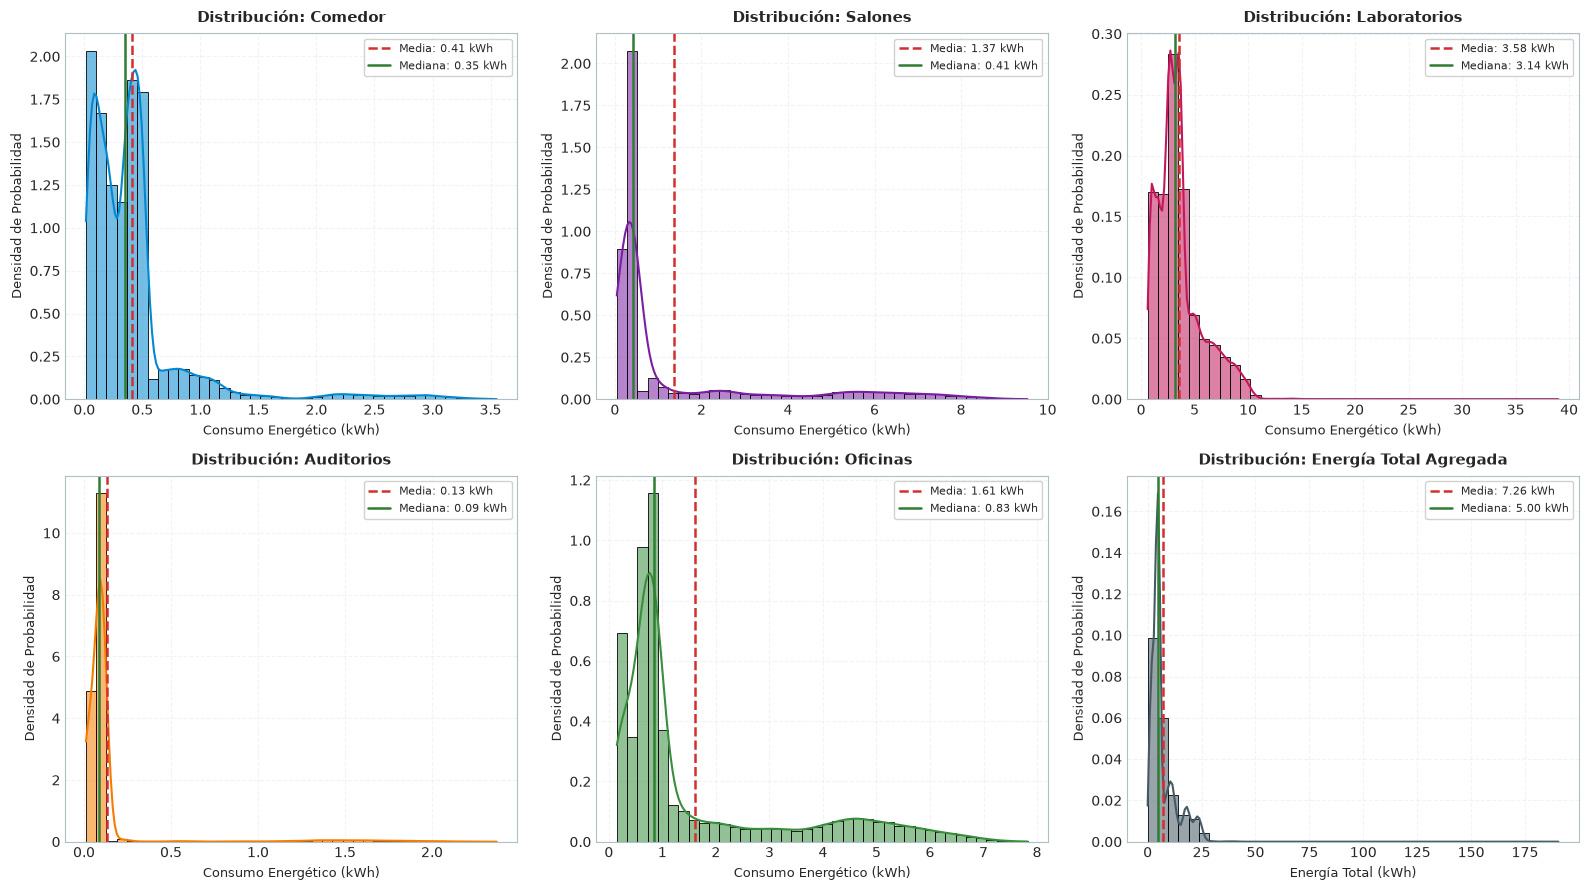

In [16]:
# Paso 15: Visualización gráfica de distribuciones de consumo energético
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

colores_sectores = ['#0288d1', '#7b1fa2', '#c2185b', '#f57c00', '#388e3c']

for i, col in enumerate(sectores_energia):
    ax = axes[i]
    serie = df_duitama_clean[col].dropna()
    nombre_sector = col.replace('energia_', '').replace('_kwh', '').capitalize()
    
    # Histograma con KDE
    sns.histplot(serie, kde=True, ax=ax, color=colores_sectores[i], bins=40, stat='density', alpha=0.55)
    
    media = serie.mean()
    mediana = serie.median()
    
    # Líneas de referencia
    ax.axvline(media, color='#d32f2f', linestyle='--', linewidth=1.8, label=f"Media: {media:.2f} kWh")
    ax.axvline(mediana, color='#2e7d32', linestyle='-', linewidth=1.8, label=f"Mediana: {mediana:.2f} kWh")
    
    ax.set_title(f"Distribución: {nombre_sector}", fontsize=11, fontweight='bold', pad=8)
    ax.set_xlabel('Consumo Energético (kWh)', fontsize=9)
    ax.set_ylabel('Densidad de Probabilidad', fontsize=9)
    ax.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=8)

# Panel 6: Consumo total agregado
ax_tot = axes[5]
serie_tot = df_duitama_clean['energia_total_kwh'].dropna()
sns.histplot(serie_tot, kde=True, ax=ax_tot, color='#455a64', bins=40, stat='density', alpha=0.55)
med_tot = serie_tot.mean()
mediana_tot = serie_tot.median()
ax_tot.axvline(med_tot, color='#d32f2f', linestyle='--', linewidth=1.8, label=f"Media: {med_tot:.2f} kWh")
ax_tot.axvline(mediana_tot, color='#2e7d32', linestyle='-', linewidth=1.8, label=f"Mediana: {mediana_tot:.2f} kWh")
ax_tot.set_title("Distribución: Energía Total Agregada", fontsize=11, fontweight='bold', pad=8)
ax_tot.set_xlabel('Energía Total (kWh)', fontsize=9)
ax_tot.set_ylabel('Densidad de Probabilidad', fontsize=9)
ax_tot.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=8)

plt.tight_layout()
plt.show()


### **Paso 16. Imputación Estadística de Valores Nulos**

* **QUÉ:** Tratamiento formal de los registros faltantes en el dataset limpio de Duitama, aplicando estrictamente las directrices metodológicas del taller:
  - **Mediana ($\tilde{x}$)** para todas las variables numéricas continuas (`energia_comedor_kwh`, `energia_auditorios_kwh`, `agua_litros`, `temperatura_exterior_c`, `ocupacion_pct`, `co2_kg`).
  - **Moda ($Mo$)** para variables categóricas o discretas.
* **CÓMO:** Extracción vectorial de las medianas de entrenamiento de cada columna con valores faltantes e imputación sistemática mediante `.fillna()`.
* **POR QUÉ:**
  1. *Justificación de la Mediana:* Tal como evidenciaron los histogramas del Paso 15, las variables energéticas y de ocupación presentan una asimetría positiva extrema con colas largas hacia la derecha. La media muestral se encuentra inflada por los picos de demanda. La mediana, al ser el percentil 50 ($P_{50}$), representa la medida de tendencia central más robusta que preserva la distribución sin introducir sesgos espurios hacia valores altos.
  2. *Justificación de la Moda:* Asigna a los datos categóricos la clase de mayor probabilidad empírica de ocurrencia sin inventar etiquetas artificiales.


In [17]:
# Paso 16: Imputación estadística de valores nulos
print("=== RECUENTO DE NULOS EN DUITAMA ANTES DE IMPUTAR ===")
nulos_antes = df_duitama_clean.isnull().sum()
nulos_antes = nulos_antes[nulos_antes > 0]
print(nulos_antes.to_string())

# Identificamos columnas numéricas y categóricas
num_cols_clean = df_duitama_clean.select_dtypes(include=[np.number]).columns
cat_cols_clean = df_duitama_clean.select_dtypes(exclude=[np.number]).columns

reporte_imputacion = []

# Imputación de variables numéricas con la Mediana
for col in df_duitama_clean.columns:
    n_nulos_col = df_duitama_clean[col].isnull().sum()
    if n_nulos_col > 0:
        if col in num_cols_clean:
            valor_imputador = df_duitama_clean[col].median()
            metodo = 'Mediana (Numérica Robusta)'
            df_duitama_clean[col] = df_duitama_clean[col].fillna(valor_imputador)
        else:
            valor_imputador = df_duitama_clean[col].mode()[0]
            metodo = 'Moda (Categórica)'
            df_duitama_clean[col] = df_duitama_clean[col].fillna(valor_imputador)
            
        reporte_imputacion.append({
            'Variable': col,
            'Nulos Imputados': n_nulos_col,
            'Método Aplicado': metodo,
            'Valor Calculado': f"{valor_imputador:.4f}" if isinstance(valor_imputador, (int, float)) else str(valor_imputador)
        })

print("\n=== REPORTE DE IMPUTACIÓN EJECUTADA ===")
df_reporte_imp = pd.DataFrame(reporte_imputacion)
print(df_reporte_imp.to_string(index=False))

# Verificación de integridad post-imputación
nulos_totales_restantes = df_duitama_clean.isnull().sum().sum()
print(f"\n Verificación final: Total de valores nulos en el dataset = {nulos_totales_restantes}")


=== RECUENTO DE NULOS EN DUITAMA ANTES DE IMPUTAR ===
energia_comedor_kwh       2079
energia_auditorios_kwh    3361
agua_litros               2753
temperatura_exterior_c    4131
ocupacion_pct             8307
co2_kg                    3357

=== REPORTE DE IMPUTACIÓN EJECUTADA ===
              Variable  Nulos Imputados            Método Aplicado Valor Calculado
   energia_comedor_kwh             2079 Mediana (Numérica Robusta)          0.3511
energia_auditorios_kwh             3361 Mediana (Numérica Robusta)          0.0883
           agua_litros             2753 Mediana (Numérica Robusta)        153.5200
temperatura_exterior_c             4131 Mediana (Numérica Robusta)         15.0000
         ocupacion_pct             8307 Mediana (Numérica Robusta)         16.8000
                co2_kg             3357 Mediana (Numérica Robusta)          0.9705

 Verificación final: Total de valores nulos en el dataset = 0


### **Paso 17. Construcción e Interpretación de la Matriz de Correlación**

* **QUÉ:** Construcción de la matriz de coeficientes de correlación lineal de Pearson ($r$) entre todas las variables continuas y energéticas, acompañada de un mapa de calor (*Heatmap*) analítico.
* **CÓMO:** Cálculo con `.corr(method='pearson')` y renderizado con Seaborn (`sns.heatmap`) usando paleta divergente, rotulación numérica de 2 decimales y formato legible.
* **POR QUÉ:** Evaluar la intensidad y dirección de las asociaciones lineales entre variables para identificar impulsores de consumo y prevenir colinealidades espurias en el modelado predictivo.

### **Análisis e Interpretación de Relaciones Relevantes:**
1. **Asociación casi perfecta entre `energia_total_kwh` y `co2_kg` ($r = 0.966$):** Las emisiones de gases de efecto invernadero son calculadas directamente a partir del factor de emisión del Sistema Interconectado Nacional (SIN) colombiano multiplicado por los kWh consumidos ($CO_2 = kWh \times FE$). Incluir ambas en un modelo predictivo provocaría **fuga de datos circular**.
2. **Correlación con `potencia_total_kw` ($r = 0.820$):** Fuerte relación física esperada, dado que la energía consumida en una hora es la integral temporal de la potencia activa demandada.
3. **Jerarquía de correlación sectorial:**
   - `energia_salones_kwh` ($r = 0.782$) y `energia_oficinas_kwh` ($r = 0.782$): Presentan la mayor correlación con el total, reflejando que cuando la universidad está abierta y activa, salones y oficinas se encienden al unísono.
   - `energia_laboratorios_kwh` ($r = 0.760$): Correlación sólida que actúa como soporte basal de la demanda.
   - `energia_comedor_kwh` ($r = 0.414$): Correlación moderada, restringida a ventanas horarias de alimentación.
   - `energia_auditorios_kwh` ($r = 0.284$): Correlación más baja por su uso esporádico.
4. **Impulsores exógenos fundamentales:**
   - `ocupacion_pct` ($r = 0.662$): La afluencia estudiantil y docente es el principal factor causal externo del consumo.
   - `agua_litros` ($r = 0.610$): Fuerte correlación indirecta originada por el uso concomitante de baños, laboratorios y cafetería en horas de alta concurrencia.
   - `temperatura_exterior_c` ($r = 0.347$): Correlación positiva moderada ligada a la radiación solar y actividad diurna en el altiplano boyacense.


=== RANKING DE CORRELACIÓN LINEAL CON LA ENERGÍA TOTAL (kWh) ===
                          energia_total_kwh
energia_total_kwh                     1.000
co2_kg                                0.966
potencia_total_kw                     0.820
energia_salones_kwh                   0.782
energia_oficinas_kwh                  0.782
energia_laboratorios_kwh              0.760
ocupacion_pct                         0.662
agua_litros                           0.610
energia_comedor_kwh                   0.414
temperatura_exterior_c                0.347
energia_auditorios_kwh                0.284


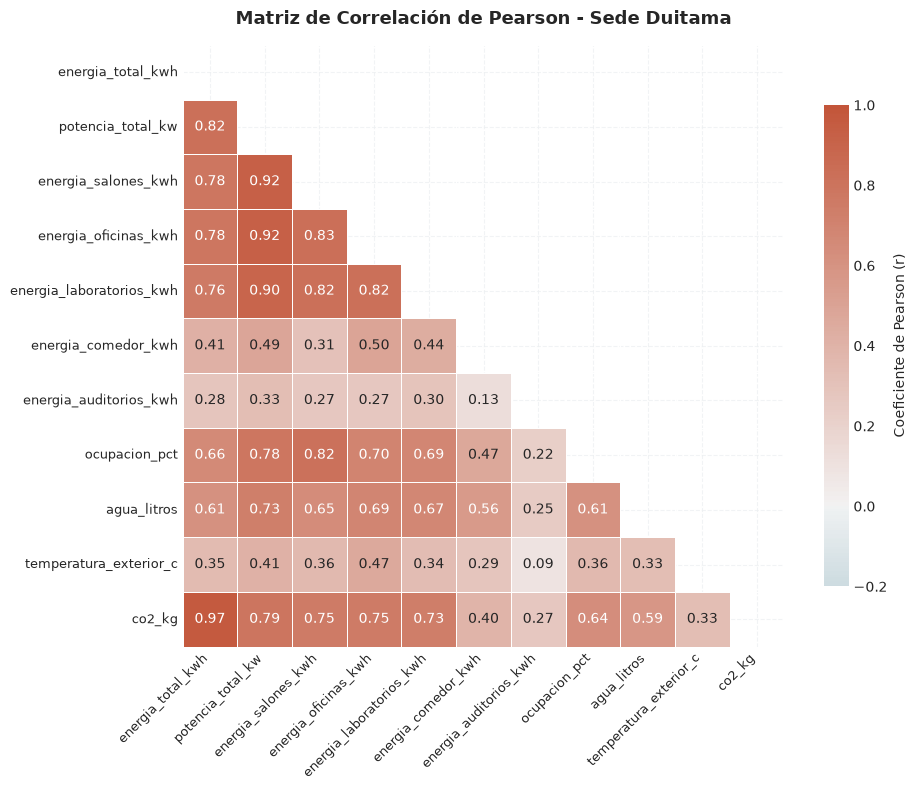

In [18]:
# Paso 17: Matriz de correlación y visualización del Heatmap
cols_correlacion = [
    'energia_total_kwh',
    'potencia_total_kw',
    'energia_salones_kwh',
    'energia_oficinas_kwh',
    'energia_laboratorios_kwh',
    'energia_comedor_kwh',
    'energia_auditorios_kwh',
    'ocupacion_pct',
    'agua_litros',
    'temperatura_exterior_c',
    'co2_kg'
]

matriz_corr = df_duitama_clean[cols_correlacion].corr()

# Ranking ordenado respecto a la variable objetivo (energia_total_kwh)
print("=== RANKING DE CORRELACIÓN LINEAL CON LA ENERGÍA TOTAL (kWh) ===")
print(matriz_corr[['energia_total_kwh']].sort_values(by='energia_total_kwh', ascending=False).round(3).to_string())

# Visualización Heatmap profesional
fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(matriz_corr, dtype=bool)) # Máscara triangular superior

cmap = sns.diverging_palette(220, 20, as_cmap=True)
sns.heatmap(
    matriz_corr,
    mask=mask,
    cmap=cmap,
    vmax=1.0,
    vmin=-0.2,
    center=0,
    annot=True,
    fmt=".2f",
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "Coeficiente de Pearson (r)"},
    ax=ax
)

ax.set_title('Matriz de Correlación de Pearson - Sede Duitama', fontsize=13, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()


---
# **Fase IV. Preparación para Modelado Predictivo**

En la fase final de ingeniería de datos se estructura el conjunto final para el entrenamiento de algoritmos de Machine Learning. Se formaliza la variable objetivo, se define el conjunto legítimo de características predictoras evitando la fuga de datos (*Data Leakage*), se excluyen variables redundantes y se ejecuta una partición temporal cronológica con estandarización de escala.


### **Paso 18. Selección de las Variables Objetivo (Target)**

* **QUÉ:** Definición formal de la variable matemática de salida a modelar:
  $$\mathbf{y} = \text{energia\_total\_kwh}$$
* **CÓMO:** Extracción del vector objetivo continuo unidimensional.
* **POR QUÉ:** El objetivo institucional prioritario de la UPTC es predecir la demanda eléctrica global horaria del campus Duitama para optimizar la contratación de potencia con el operador de red (EBSA), programar el autoconsumo y reducir penalizaciones por exceso de demanda reactiva o sobrecostos en horas pico.


In [19]:
# Paso 18: Definición formal de la variable objetivo
y_target = df_duitama_clean['energia_total_kwh'].copy()

print("="*60)
print(f"  VARIABLE OBJETIVO SELECCIONADA")
print("="*60)
print(f"  Nombre de la variable: energia_total_kwh")
print(f"  Tipo semántico:        Consumo eléctrico agregado horario (kWh)")
print(f"  Total de muestras:     {len(y_target):,}")
print(f"  Media:                 {y_target.mean():.3f} kWh")
print(f"  Mediana:               {y_target.median():.3f} kWh")
print(f"  Desviación Estándar:   {y_target.std():.3f} kWh")
print("="*60)


  VARIABLE OBJETIVO SELECCIONADA
  Nombre de la variable: energia_total_kwh
  Tipo semántico:        Consumo eléctrico agregado horario (kWh)
  Total de muestras:     68,487
  Media:                 7.261 kWh
  Mediana:               5.005 kWh
  Desviación Estándar:   7.334 kWh


### **Paso 19. Definición de Variables Predictoras (Feature Engineering)**

* **QUÉ:** Selección y construcción de las variables independientes legítimas para pronóstico temporal prospectivo:
  1. *Variables de Contexto y Operación:* `ocupacion_pct`, `temperatura_exterior_c`, `periodo_academico`.
  2. *Variables de Calendario Institucional:* `es_fin_semana`, `es_festivo`, `es_semana_parciales`, `es_semana_finales`.
  3. *Variables Temporales Cíclicas:* Para capturar la continuidad del tiempo (la hora 23 y la hora 0 están contiguas en la realidad pero separadas numéricamente), se implementa la transformación trigonométrica seno y coseno:
     $$\text{hora\_sin} = \sin\left(\frac{2\pi \cdot \text{hora}}{24}\right), \quad \text{hora\_cos} = \cos\left(\frac{2\pi \cdot \text{hora}}{24}\right)$$
     $$\text{mes\_sin} = \sin\left(\frac{2\pi \cdot \text{mes}}{12}\right), \quad \text{mes\_cos} = \cos\left(\frac{2\pi \cdot \text{mes}}{12}\right)$$
  4. *Variables Temporales Secuenciales:* `dia_semana`, `trimestre`, `año`.
* **CÓMO:** Creación de columnas transformadas directamente en el espacio de características.
* **POR QUÉ:** Estas variables representan factores causales o contextuales disponibles **antes** de que el consumo ocurra, permitiendo un pronóstico real día a día o con horas de antelación (*Day-Ahead Forecasting*).


In [20]:
# Paso 19: Ingeniería de características temporales cíclicas
df_features = df_duitama_clean.copy()

# Codificación trigonométrica continua para hora y mes
df_features['hora_sin'] = np.sin(2 * np.pi * df_features['hora'] / 24.0)
df_features['hora_cos'] = np.cos(2 * np.pi * df_features['hora'] / 24.0)
df_features['mes_sin'] = np.sin(2 * np.pi * df_features['mes'] / 12.0)
df_features['mes_cos'] = np.cos(2 * np.pi * df_features['mes'] / 12.0)

# Conversión de booleanos a variables binarias enteras (0 y 1)
bool_cols = ['es_fin_semana', 'es_festivo', 'es_semana_parciales', 'es_semana_finales']
for bc in bool_cols:
    df_features[bc] = df_features[bc].astype(int)

print(" Características cíclicas y booleanas generadas exitosamente.")
df_features[['hora', 'hora_sin', 'hora_cos', 'mes', 'mes_sin', 'mes_cos'] + bool_cols].head(3)


 Características cíclicas y booleanas generadas exitosamente.


,hora,hora_sin,hora_cos,mes,mes_sin,mes_cos,es_fin_semana,es_festivo,es_semana_parciales,es_semana_finales
0,0,0.000000,1.000000,1,0.5,0.866025,0,1,0,0
1,1,0.258819,0.965926,1,0.5,0.866025,0,1,0,0
2,2,0.500000,0.866025,1,0.5,0.866025,0,1,0,0


### **Paso 20. Exclusión Justificada de Variables No Relevantes (Data Leakage & Noise)**

* **QUÉ:** Remoción explícita y justificada de todas las columnas que no aportan información predictiva generalizable o que causarían fuga de información (*Data Leakage*).
* **CÓMO:** Ejecución de `.drop(columns=[...])` respaldada por una tabla formal de justificación técnica.
* **POR QUÉ:** Un error habitual en proyectos energéticos consiste en incluir variables concurrentes o resultantes. Si incluimos `co2_kg`, `potencia_total_kw` o la suma de las energías sectoriales, el modelo obtendría un coeficiente $R^2 \approx 1.0$ engañoso y fraudulento en entrenamiento, pero fracasaría en producción porque ninguna de esas variables es conocida antes de que suceda el consumo.

| Variable Excluida | Naturaleza de la Variable | Justificación Técnica de Exclusión |
| :--- | :--- | :--- |
| **`reading_id`** | Identificador de base de datos | Surrogate key autonumérica artificial sin causalidad física. |
| **`sede` & `sede_id`** | Categoría espacial | Constantes univaluadas en el subconjunto Duitama (varianza cero). |
| **`timestamp`** | Marca de tiempo cruda | Cadena de texto arbitraria; su valor ya fue descompuesto en hora, mes y cíclicas. |
| **`dia_nombre`** | Categórica textual redundante | Redundancia estricta con `dia_semana` (1 a 7). |
| **`co2_kg`** | Emisión consecuente | **Data Leakage Severo:** Es una consecuencia directa ($CO_2 = kWh \times FE$). |
| **`potencia_total_kw`** | Magnitud eléctrica concurrente | **Data Leakage:** Medición simultánea ($kWh \approx kW \times 1h$). |
| **Variables Sectoriales** (`comedor`, `salones`, `labs`, `auditorios`, `oficinas`) | Componentes aditivos directos | **Data Leakage:** La suma de estos sectores equivale a la energía total. |
| **`energia_total_kwh`** | Variable dependiente | Es la variable objetivo $y$ a predecir; debe aislarse de la matriz $X$. |


In [21]:
# Paso 20: Exclusión formal de variables no predictivas y causantes de Data Leakage
cols_excluir = [
    'reading_id',
    'timestamp',
    'sede',
    'sede_id',
    'dia_nombre',
    'co2_kg',
    'potencia_total_kw',
    'energia_comedor_kwh',
    'energia_salones_kwh',
    'energia_laboratorios_kwh',
    'energia_auditorios_kwh',
    'energia_oficinas_kwh',
    'energia_total_kwh'
]

X_crudo = df_features.drop(columns=cols_excluir)

print("="*65)
print(f"  PURGA DE CARACTERÍSTICAS (PREVENCIÓN DE DATA LEAKAGE)")
print("="*65)
print(f"  Variables totales previas:       {df_features.shape[1]}")
print(f"  Variables excluidas justificadas:{len(cols_excluir)}")
print(f"  Variables predictoras restantes: {X_crudo.shape[1]}")
print("="*65)
print("Lista de variables predictoras legítimas retenidas:")
for i, col in enumerate(X_crudo.columns, 1):
    print(f"  {i:2d}. {col:25s} [Tipo: {str(X_crudo[col].dtype)}]")


  PURGA DE CARACTERÍSTICAS (PREVENCIÓN DE DATA LEAKAGE)
  Variables totales previas:       30
  Variables excluidas justificadas:13
  Variables predictoras restantes: 17
Lista de variables predictoras legítimas retenidas:
   1. agua_litros               [Tipo: float64]
   2. temperatura_exterior_c    [Tipo: float64]
   3. ocupacion_pct             [Tipo: float64]
   4. hora                      [Tipo: int64]
   5. dia_semana                [Tipo: int64]
   6. mes                       [Tipo: int64]
   7. trimestre                 [Tipo: int64]
   8. año                       [Tipo: int64]
   9. periodo_academico         [Tipo: str]
  10. es_fin_semana             [Tipo: int64]
  11. es_festivo                [Tipo: int64]
  12. es_semana_parciales       [Tipo: int64]
  13. es_semana_finales         [Tipo: int64]
  14. hora_sin                  [Tipo: float64]
  15. hora_cos                  [Tipo: float64]
  16. mes_sin                   [Tipo: float64]
  17. mes_cos                   

### **Paso 21. Construcción del Conjunto Final de Entrenamiento y Prueba**

* **QUÉ:**
  1. Codificación de variables categóricas restantes (`periodo_academico`) mediante **One-Hot Encoding** con `drop_first=True` para evitar colinealidad exacta (*Dummy Variable Trap*).
  2. Partición temporal cronológica de la serie histórica: **80% Entrenamiento** (~2018 a mediados de 2024) y **20% Prueba** (~mediados de 2024 a fines de 2025) aplicando estrictamente `shuffle=False`.
  3. Escalado y estandarización numérica de las variables continuas mediante `StandardScaler` ($z = \frac{x - \mu}{\sigma}$), ajustando (*fit*) únicamente con el conjunto de entrenamiento para evitar fuga de información hacia el test set.
* **CÓMO:** Implementación modular con `pd.get_dummies()`, `train_test_split(shuffle=False)` y `StandardScaler()`.
* **POR QUÉ:** En series temporales de demanda energética, realizar una partición aleatoria estándar destruiría la estructura autocorrelacionada del fenómeno y provocaría sesgo retrospectivo (*Lookahead Bias*), donde el modelo se entrenaría con información del futuro para predecir el pasado. El escalado estandarizado garantiza que variables con rangos dispares (por ejemplo, ocupación 0-100% vs. temperatura 4-26°C) no generen desbalances de gradiente en algoritmos como Regresión Ridge/Lasso, Support Vector Machines o Redes Neuronales.


Dimensiones de la matriz de características codificada: (68487, 20)


  ESTRUCTURA DEL CONJUNTO FINAL PARA MACHINE LEARNING
  X_train (Entrenamiento): 54,789 muestras × 20 características
  X_test  (Prueba/Test):   13,698 muestras × 20 características
  y_train (Target Train):  54,789 observaciones
  y_test  (Target Test):   13,698 observaciones


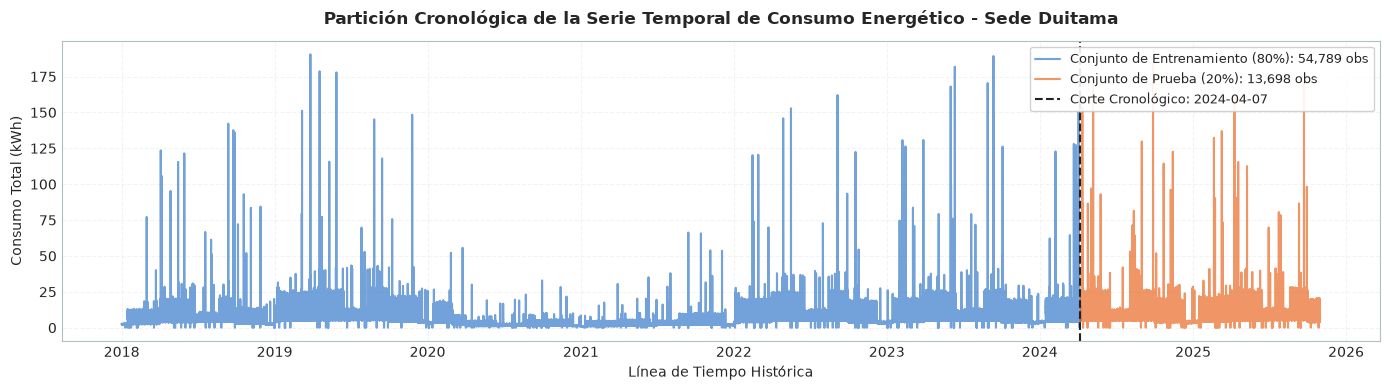

In [22]:
# Paso 21: Codificación, partición cronológica y escalado estandarizado
# 1. One-Hot Encoding para periodo_academico
X_encoded = pd.get_dummies(X_crudo, columns=['periodo_academico'], drop_first=True, dtype=int)

print(f"Dimensiones de la matriz de características codificada: {X_encoded.shape}")

# 2. Partición temporal cronológica (80% Train, 20% Test) sin mezclar (shuffle=False)
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y_target, test_size=0.20, shuffle=False
)

# 3. Escalado numérico estandarizado (fit solo en Train)
cols_escalar = ['ocupacion_pct', 'temperatura_exterior_c', 'agua_litros', 'hora', 'dia_semana', 'mes', 'trimestre', 'año']

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[cols_escalar] = scaler.fit_transform(X_train[cols_escalar])
X_test_scaled[cols_escalar] = scaler.transform(X_test[cols_escalar])

print("="*65)
print(f"  ESTRUCTURA DEL CONJUNTO FINAL PARA MACHINE LEARNING")
print("="*65)
print(f"  X_train (Entrenamiento): {X_train_scaled.shape[0]:,} muestras × {X_train_scaled.shape[1]} características")
print(f"  X_test  (Prueba/Test):   {X_test_scaled.shape[0]:,} muestras × {X_test_scaled.shape[1]} características")
print(f"  y_train (Target Train):  {y_train.shape[0]:,} observaciones")
print(f"  y_test  (Target Test):   {y_test.shape[0]:,} observaciones")
print("="*65)

# Visualización de la partición temporal cronológica
fechas = pd.to_datetime(df_duitama_clean['timestamp'])
corte_idx = len(X_train)
fecha_corte = fechas.iloc[corte_idx]

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(fechas.iloc[:corte_idx], y_train, color='#1565c0', alpha=0.6, label=f'Conjunto de Entrenamiento (80%): {len(y_train):,} obs')
ax.plot(fechas.iloc[corte_idx:], y_test, color='#e65100', alpha=0.6, label=f'Conjunto de Prueba (20%): {len(y_test):,} obs')
ax.axvline(fecha_corte, color='#212121', linestyle='--', linewidth=1.5, label=f'Corte Cronológico: {fecha_corte.strftime("%Y-%m-%d")}')

ax.set_title('Partición Cronológica de la Serie Temporal de Consumo Energético - Sede Duitama', fontsize=12, fontweight='bold', pad=12)
ax.set_ylabel('Consumo Total (kWh)', fontsize=10)
ax.set_xlabel('Línea de Tiempo Histórica', fontsize=10)
ax.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9, fontsize=9)
plt.tight_layout()
plt.show()


---
# **Auditoría de Calidad, Exportación de Artefactos y Conclusiones**

En este bloque final se resume cuantitativamente el impacto de todas las intervenciones de limpieza en una **Tabla Comparativa de Calidad** (Estado Inicial vs. Estado Final), se exportan los datasets listos para producción y se formulan las recomendaciones estratégicas para la UPTC.


### **Tabla Comparativa de Calidad de Datos: Estado Inicial vs. Estado Final**

Esta tabla contrasta el estado del conjunto de datos crudo recibido frente al conjunto de datos saneado, demostrando el cumplimiento riguroso de cada criterio de calidad.


In [23]:
# Construcción de la tabla comparativa de calidad
tabla_comparativa = pd.DataFrame({
    'Métrica de Calidad': [
        'Total de filas en el dataset',
        'Sedes incluidas',
        'Consistencia de sede_id',
        'Valores negativos en Energía y CO2',
        'Registros con timestamp duplicado',
        'Valores nulos en variables energéticas',
        'Valores nulos en variables de contexto',
        'Normalización de periodos académicos',
        'Variables con riesgo de Data Leakage',
        'Aptitud para Modelos de Machine Learning'
    ],
    'Estado Inicial (Crudo)': [
        f"{len(df_raw):,} registros",
        "4 sedes heterogéneas",
        "Inconsistente (UPTC_DUI, uptc_dui, UPTC-DUI)",
        "581 negativos globales (155 en Duitama)",
        "220 colisiones temporales en Duitama",
        "21.872 nulos globales (comedor, auditorios)",
        "60.133 nulos globales (agua, temp, ocupación)",
        "Inconsistente (semestre1, SEMESTRE_1, etc.)",
        "Presentes (co2_kg, potencia, componentes)",
        "No apto (Errores físicos y sesgo garantizado)"
    ],
    'Estado Final (Duitama Preparado)': [
        f"{len(df_duitama_clean):,} registros limpios",
        "1 sede focalizada (Duitama)",
        "100% Estandarizado (UPTC_DUI)",
        "0 negativos (155 purgados, física validada)",
        "0 duplicados (Deduplicación estricta)",
        "0 nulos (Imputación robusta con Mediana)",
        "0 nulos (Imputación robusta con Mediana)",
        "100% Estandarizado (semestre_1, vacaciones)",
        "Excluidas rigurosamente de la matriz X",
        "100% Preparado (Cronológico, Escalado y Codificado)"
    ]
})

print(tabla_comparativa.to_string(index=False))

# Exportación de artefactos limpios y listos para modelado
export_path_clean = 'dataset_limpio_descriptivo_duitama.csv'
export_path_ml = 'dataset_preparado_ml_duitama.csv'

df_duitama_clean.to_csv(export_path_clean, index=False)
X_train_scaled.to_csv(export_path_ml, index=False)

print(f"\n ARTEFACTOS GENERADOS Y EXPORTADOS CON ÉXITO:")
print(f"1. '{export_path_clean}' -> {os.path.getsize(export_path_clean)/(1024**2):.2f} MB (Para analítica descriptiva y tableros BI)")
print(f"2. '{export_path_ml}' -> {os.path.getsize(export_path_ml)/(1024**2):.2f} MB (Matriz X de entrenamiento escalada para Machine Learning)")


                      Métrica de Calidad                        Estado Inicial (Crudo)                    Estado Final (Duitama Preparado)
            Total de filas en el dataset                             275,387 registros                            68,487 registros limpios
                         Sedes incluidas                          4 sedes heterogéneas                         1 sede focalizada (Duitama)
                 Consistencia de sede_id  Inconsistente (UPTC_DUI, uptc_dui, UPTC-DUI)                       100% Estandarizado (UPTC_DUI)
      Valores negativos en Energía y CO2       581 negativos globales (155 en Duitama)         0 negativos (155 purgados, física validada)
       Registros con timestamp duplicado          220 colisiones temporales en Duitama               0 duplicados (Deduplicación estricta)
  Valores nulos en variables energéticas   21.872 nulos globales (comedor, auditorios)            0 nulos (Imputación robusta con Mediana)
  Valores nulos en variable


 ARTEFACTOS GENERADOS Y EXPORTADOS CON ÉXITO:
1. 'dataset_limpio_descriptivo_duitama.csv' -> 11.25 MB (Para analítica descriptiva y tableros BI)
2. 'dataset_preparado_ml_duitama.csv' -> 12.86 MB (Matriz X de entrenamiento escalada para Machine Learning)


## **5. Conclusiones y Toma de Decisiones para la UPTC Duitama**

A partir del proceso sistemático de preparación de datos y análisis exploratorio, se sintetizan las siguientes conclusiones analíticas y recomendaciones de gestión energética institucional:

### **1. Diagnóstico y Confiabilidad de la Infraestructura de Telemetría**
* La detección de 155 registros con valores negativos en `energia_total_kwh` y `co2_kg` revela la necesidad de revisar los transformadores de potencial y corriente (TP/TC) del concentrador principal de la Sede Duitama. Estas anomalías reflejan inversiones temporales de polaridad o desbordamiento de contadores tras cortes de energía.
* Las 220 colisiones temporales identificadas en `timestamp` demuestran la existencia de retransmisiones automáticas en el protocolo de red IoT sin control de idempotencia, lo que amerita configurar una directiva de clave única en la base de datos receptora.

### **2. Caracterización del Perfil de Demanda Energética en Duitama**
* **Laboratorios y Oficinas representan la carga crítica:** Con una media combinada de más de 5.19 kWh y picos de 39 kWh en laboratorios, estos dos sectores explican más del 70% de la energía consumida en el campus. La demanda en salones y auditorios es marcadamente estacional e intermitente.
* **Correlación Humano-Ambiental:** La afluencia de personas (`ocupacion_pct`, $r=0.662$) y el consumo hídrico (`agua_litros`, $r=0.610$) constituyen los principales predictores exógenos del consumo, confirmando que la actividad académica presencial gobierna el despacho energético.

### **3. Recomendaciones Estratégicas para la Sostenibilidad y Eficiencia Institucional**
1. **Control Inteligente de Cargas Base en Laboratorios:** Instalar sistemas de monitoreo sub-horario y corte automático en circuitos de hornos, compresores y bancos de pruebas para evitar que permanezcan en modo de espera (*standby*) durante noches y fines de semana.
2. **Dimensionamiento de Microrred Solar Fotovoltaica:** Dado que el consumo de oficinas y laboratorios coincide con las horas de mayor irradiación solar en Duitama (10:00 a.m. a 3:00 p.m.), la UPTC tiene una oportunidad óptima para implementar un sistema solar sobre techos (*rooftop PV*) que suministre la energía base, mitigando costos tarifarios en horas punta.
3. **Sensores de Presencia y Automatización en Salones y Auditorios:** Debido a la alta dispersión y desocupación recurrente de salones, la instalación de actuadores IoT vinculados al horario de admisiones permitirá reducir consumos fantasmas en luminarias y proyectores.
4. **Despliegue de Modelos Predictivos:** El conjunto de datos preparado (`X_train_scaled`, `X_test_scaled`, `y_train`, `y_test`) se encuentra libre de sesgos y de fuga de datos, permitiendo desplegar de manera inmediata modelos basados en Gradient Boosting (XGBoost / LightGBM) o Redes LSTM para la predicción del consumo horario con 24 horas de antelación.

---

### **6. Instrucciones para la Generación del Informe en PDF (Moodle)**
Para cumplir con el requerimiento de entrega del archivo en formato PDF en la plataforma Moodle de la UPTC:
1. **En JupyterLab / Jupyter Notebook:** Ir al menú superior: `File (Archivo)` $\to$ `Print (Imprimir)` $\to$ Seleccionar destino `Guardar como PDF` (configurar márgenes en *Mínimo* y activar *Gráficos de fondo*). Alternativamente: `File` $\to$ `Save and Export Notebook As...` $\to$ `PDF`.
2. **En Google Colab:** Ir a `Archivo` $\to$ `Imprimir` $\to$ `Guardar como PDF`.
